# 01 - Clean the OCT data and build a proper dataset
Turns the raw Kaggle OCT folders into **one clean, patient-disjoint, standardised dataset** that every later notebook can use.
No PyTorch needed.

**Pipeline**
1. **Scan** every file once: size, brightness/contrast, file hash (exact duplicates), 256-bit difference hash (near duplicates), patient ID from the file name.
2. **Remove invalid data** - the image equivalent of NaN: unreadable or empty files, non-finite pixel values, too-small images, blank scans, files without a patient ID.
3. **Remove duplicates** - identical images under *different* class folders are dropped completely (label cannot be trusted); other exact copies keep one scan.
4. **Group patients** - patients are linked when they share an image or have near-identical scans, so a group can never straddle train/val/test.
5. **Split by group**, stratified by class: `new_split` (80/10/10 over everything, big test set) or `official_test` (keep the original test scans, make sure nothing leaks into train).
6. **Standardise** - grayscale, one fixed size (default 256 x 256), lossless PNG.
7. **Verify** the written dataset (readable, finite, no overlap, no duplicates) and write a manifest, an audit list of everything removed, dataset statistics and a README.

Output: `OUT_ROOT/{train,val,test}/{CNV,DME,DRUSEN,NORMAL}/*.png` + `manifest.csv`, `dropped.csv`, `stats.json`, `README.md`.
Takes roughly 10-15 minutes. Safe to re-run (finished steps are cached).

## 1. Settings

In [1]:
import io, re, csv, json, math, time, random, hashlib, collections
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw):
        return x

# ---------------- settings ----------------
RAW_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT2017")      # folder that contains train/ and test/
OUT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_clean")    # the new dataset is written here

SPLIT_MODE = "new_split"        # "new_split": regroup everything 80/10/10 by patient (largest, most reliable test set)
                                # "official_test": keep the original test scans, remove anything linked to them from train/val
SPLIT_FRACS = (0.8, 0.1, 0.1)   # train / val / test (new_split); official_test uses train:val = 0.8:0.1
SEED = 42

OUT_SIZE = 256                  # final image size (square)
RESIZE_MODE = "squash"          # "squash" (keep all content) | "pad" (keep aspect ratio, black borders) | "center_crop"
SAVE_FORMAT = "png"             # "png" (lossless, about 4-5 GB) | "jpg" (about 2 GB)
JPG_QUALITY = 95

MIN_SIDE = 128                  # smaller images are treated as invalid
BLANK_STD, BLANK_DARK, BLANK_BRIGHT = 4.0, 3.0, 252.0     # near-uniform / near-black / near-white
DROP_BAD_NAME = False           # True: also drop files whose name has no patient ID (otherwise each is its own group)
NEAR_BITS = 7                   # near-duplicate = difference hashes differ in <= 7 of 256 bits
MAX_BUCKET = 400
WORKERS = 8
FORCE = False                   # True = ignore the cached scan and rewrite every image
# -------------------------------------------

assert SPLIT_MODE in ("new_split", "official_test") and abs(sum(SPLIT_FRACS) - 1) < 1e-6
assert RESIZE_MODE in ("squash", "pad", "center_crop") and SAVE_FORMAT in ("png", "jpg")
EXT = SAVE_FORMAT
WORK = OUT_ROOT / "_work"
WORK.mkdir(parents=True, exist_ok=True)

EXTS = {".jpeg", ".jpg", ".png"}
NAME_RE = re.compile(r"^([A-Za-z]+)-(\d+)-(\d+)$")        # e.g. CNV-1016042-1
RES = getattr(Image, "Resampling", Image)
bitcount = int.bit_count if hasattr(int, "bit_count") else (lambda x: bin(x).count("1"))

if not (RAW_ROOT / "train").is_dir():
    raise FileNotFoundError(f"No 'train' folder under {RAW_ROOT}. Point RAW_ROOT at the folder that directly contains train/ and test/.")
SPLITS_RAW = [s for s in ("train", "val", "test") if (RAW_ROOT / s).is_dir()]
CLASSES = sorted(p.name for p in (RAW_ROOT / "train").iterdir() if p.is_dir())
K = len(CLASSES)
print("Raw data:", RAW_ROOT, "| splits:", SPLITS_RAW, "| classes:", CLASSES)
print("Clean dataset will be written to:", OUT_ROOT)

Raw data: C:\Users\User\Desktop\retinaldataset\OCT2017 | splits: ['train', 'val', 'test'] | classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Clean dataset will be written to: C:\Users\User\Desktop\retinaldataset\OCT_clean


c:\Users\User\Desktop\RAG-1\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Scan the raw dataset
One pass over every file (cached in `_work/index.csv`). Besides the hashes it records everything needed to spot invalid data:
unreadable or empty files, non-finite pixel values, tiny images, missing patient ID in the file name.

In [2]:
FIELDS = ["path", "split", "cls", "pid", "name_ok", "ok", "reason", "w", "h", "md5", "dhash", "mean", "std"]

def file_record(job):
    path, split, cls = job
    m = NAME_RE.match(path.stem)
    rec = dict(path=str(path), split=split, cls=cls, pid=m.group(2) if m else "", name_ok=int(bool(m)),
               ok=1, reason="", w=0, h=0, md5="", dhash="", mean=0.0, std=0.0)
    try:
        data = path.read_bytes()
        if len(data) == 0:
            raise ValueError("empty file")
        rec["md5"] = hashlib.md5(data).hexdigest()
        im = Image.open(io.BytesIO(data))
        im.load()
        rec["w"], rec["h"] = im.size
        if min(im.size) < MIN_SIDE:
            raise ValueError(f"image too small ({im.size[0]}x{im.size[1]})")
        g = im.convert("L")
        small = np.asarray(g.resize((17, 16), RES.BILINEAR), dtype=np.float32)
        thumb = np.asarray(g.resize((64, 64), RES.BILINEAR), dtype=np.float32)
        if not (np.isfinite(small).all() and np.isfinite(thumb).all()):
            raise ValueError("non-finite pixel values")
        rec["dhash"] = np.packbits((small[:, 1:] > small[:, :-1]).flatten()).tobytes().hex()
        rec["mean"], rec["std"] = float(thumb.mean()), float(thumb.std())
        if not (np.isfinite(rec["mean"]) and np.isfinite(rec["std"])):
            raise ValueError("non-finite image statistics")
    except Exception as e:
        rec["ok"], rec["reason"] = 0, f"{type(e).__name__}: {e}"[:120]
    return rec

INDEX_CSV = WORK / "index.csv"
if INDEX_CSV.exists() and not FORCE:
    with open(INDEX_CSV, newline="", encoding="utf-8") as f:
        R = list(csv.DictReader(f))
    for r in R:
        for k in ("name_ok", "ok", "w", "h"):
            r[k] = int(r[k])
        r["mean"], r["std"] = float(r["mean"]), float(r["std"])
    print(f"Loaded cached scan: {len(R):,} files")
else:
    jobs = []
    for split in SPLITS_RAW:
        for cls in CLASSES:
            d = RAW_ROOT / split / cls
            if d.is_dir():
                for name in sorted(p.name for p in d.iterdir()):
                    if Path(name).suffix.lower() in EXTS:
                        jobs.append((d / name, split, cls))
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        R = list(tqdm(ex.map(file_record, jobs), total=len(jobs), desc="scanning"))
    with open(INDEX_CSV, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=FIELDS)
        w.writeheader()
        w.writerows(R)
    print(f"Scanned {len(R):,} files in {(time.time() - t0) / 60:.1f} min")

scanning: 100%|██████████| 84484/84484 [00:45<00:00, 1860.09it/s]


Scanned 84,484 files in 0.8 min


## 3. What the raw data looks like

In [3]:
print("Files per split and class")
print("  " + "split".ljust(6) + "".join(c.rjust(9) for c in CLASSES) + "    total")
for s in SPLITS_RAW:
    row = [sum(1 for r in R if r["split"] == s and r["cls"] == c) for c in CLASSES]
    print("  " + s.ljust(6) + "".join(f"{n:9,d}" for n in row) + f"{sum(row):9,d}")

print(f"\nInvalid files (unreadable / empty / non-finite / too small): {sum(1 for r in R if not r['ok'])}")
for reason, n in collections.Counter(r["reason"].split(":")[0] if r["reason"].startswith(("Unidentified", "OSError")) else r["reason"].split(" (")[0]
                                      for r in R if not r["ok"]).most_common(5):
    print(f"   {n:5d}  {reason}")
print(f"Files without a patient ID in the name: {sum(1 for r in R if not r['name_ok'])}")

pid_cls = collections.defaultdict(set)
for r in R:
    if r["pid"]:
        pid_cls[r["pid"]].add(r["cls"])
print(f"Patient IDs: {len(pid_cls):,} | IDs that appear under more than one class folder: "
      f"{sum(len(v) > 1 for v in pid_cls.values())}")

sizes = collections.Counter((r["w"], r["h"]) for r in R if r["ok"])
print("\nImage sizes (w x h):", ", ".join(f"{w}x{h}: {n:,}" for (w, h), n in sizes.most_common(6)))

# does image size alone predict the class? (a shortcut a network could exploit)
by_size = collections.defaultdict(collections.Counter)
for r in R:
    if r["ok"] and r["split"] == "train":
        by_size[(r["w"], r["h"])][r["cls"]] += 1
print("\nTrain scans per image size (share of each class):")
for size, c in sorted(by_size.items(), key=lambda kv: -sum(kv[1].values())):
    n = sum(c.values())
    print(f"  {size[0]:4d} x {size[1]:3d}  n={n:6,d} | " + "  ".join(f"{k} {c[k] / n * 100:3.0f}%" for k in CLASSES))
majority = {size: c.most_common(1)[0][0] for size, c in by_size.items()}
test_ok = [r for r in R if r["ok"] and r["split"] == "test"]
if test_ok:
    hit = sum(majority.get((r["w"], r["h"])) == r["cls"] for r in test_ok)
    print(f"\nPredicting the class from image size alone: {hit / len(test_ok) * 100:.1f}% on the official test set (chance {100 / K:.0f}%).")

Files per split and class
  split       CNV      DME   DRUSEN   NORMAL    total
  train    37,205   11,348    8,616   26,315   83,484
  val           8        8        8        8       32
  test        242      242      242      242      968

Invalid files (unreadable / empty / non-finite / too small): 0
Files without a patient ID in the name: 0
Patient IDs: 4,657 | IDs that appear under more than one class folder: 896

Image sizes (w x h): 512x496: 38,661, 768x496: 21,715, 512x512: 15,456, 1536x496: 8,362, 1024x496: 274, 384x496: 16

Train scans per image size (share of each class):
   512 x 496  n=37,892 | CNV  53%  DME   4%  DRUSEN  14%  NORMAL  29%
   768 x 496  n=21,485 | CNV  56%  DME   4%  DRUSEN  12%  NORMAL  28%
   512 x 512  n=15,456 | CNV   0%  DME  56%  DRUSEN   0%  NORMAL  44%
  1536 x 496  n= 8,361 | CNV  60%  DME   4%  DRUSEN   8%  NORMAL  27%
  1024 x 496  n=   274 | CNV  63%  DME   5%  DRUSEN   8%  NORMAL  23%
   384 x 496  n=    16 | CNV  94%  DME   0%  DRUSEN   0%  N

## 4. Cleaning
Every file gets a status (`keep` or `drop`) and a reason, so nothing disappears silently (see `dropped.csv` at the end).

In [4]:
class UnionFind:
    def __init__(self):
        self.p = {}
    def find(self, x):
        self.p.setdefault(x, x)
        root = x
        while self.p[root] != root:
            root = self.p[root]
        while self.p[x] != root:
            nxt = self.p[x]
            self.p[x] = root
            x = nxt
        return root
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[rb] = ra

uf = UnionFind()
PRIORITY = {"test": 0, "val": 1, "train": 2}        # which copy to keep when an image appears twice
node = lambda r: r["pid"] if r["pid"] else "file:" + r["path"]     # patient (or the file itself if no ID)

for r in R:
    r["status"], r["drop_reason"] = "keep", ""
def drop(r, reason):
    if r["status"] == "keep":
        r["status"], r["drop_reason"] = "drop", reason
n_keep = lambda: sum(r["status"] == "keep" for r in R)
FUNNEL = [("raw files", len(R))]

# (a) invalid data: unreadable, empty, non-finite, too small
for r in R:
    if not r["ok"]:
        drop(r, "invalid file: " + r["reason"].split(":")[0])
FUNNEL.append(("valid images", n_keep()))

# (b) blank / near-uniform scans
for r in R:
    if r["status"] == "keep" and (r["std"] < BLANK_STD or r["mean"] < BLANK_DARK or r["mean"] > BLANK_BRIGHT):
        drop(r, "blank or near-uniform scan")
FUNNEL.append(("not blank", n_keep()))

# (c) missing patient ID (metadata missing)
if DROP_BAD_NAME:
    for r in R:
        if not r["name_ok"]:
            drop(r, "file name has no patient ID")
    FUNNEL.append(("has patient ID", n_keep()))

# (d) exact duplicates
by_md5 = collections.defaultdict(list)
for i, r in enumerate(R):
    if r["status"] == "keep":
        by_md5[r["md5"]].append(i)
dups = {k: v for k, v in by_md5.items() if len(v) > 1}
for idxs in dups.values():                                   # patients that share an image belong together
    for i in idxs[1:]:
        uf.union(node(R[idxs[0]]), node(R[i]))

conflict_groups = 0
for idxs in dups.values():                                   # same image, different class folders -> label unreliable
    if len({R[i]["cls"] for i in idxs}) > 1:
        conflict_groups += 1
        for i in idxs:
            drop(R[i], "same image under different class folders")
FUNNEL.append(("no label conflicts", n_keep()))

for idxs in dups.values():                                   # same class: keep a single copy
    live = sorted((i for i in idxs if R[i]["status"] == "keep"), key=lambda i: (PRIORITY.get(R[i]["split"], 3), R[i]["path"]))
    for i in live[1:]:
        drop(R[i], "exact duplicate (one copy kept)")
FUNNEL.append(("no exact duplicates", n_keep()))

print(f"Exact-duplicate groups: {len(dups):,} (of which {conflict_groups:,} have conflicting class folders)")
for (label, n), (_, prev) in zip(FUNNEL[1:], FUNNEL[:-1]):
    print(f"  {label:28s} {n:7,d} left   (removed {prev - n:,})")

Exact-duplicate groups: 6,779 (of which 225 have conflicting class folders)
  valid images                  84,484 left   (removed 0)
  not blank                     84,484 left   (removed 0)
  no label conflicts            84,018 left   (removed 466)
  no exact duplicates           76,677 left   (removed 7,341)


## 5. Near duplicates and patient groups
Scans whose 256-bit difference hashes differ in at most 7 bits are the same picture re-saved or re-compressed.
They are not deleted (they might be genuine neighbouring slices) but their patients are **linked**, so they always end up in the same split.

In [5]:
def near_pairs(ids, hex_hashes, chunk=8, max_bucket=MAX_BUCKET):
    # two 256-bit hashes that differ in <= 7 bits always share one of their 8 chunks of 32 bits
    ints = {i: int(hex_hashes[i], 16) for i in ids}
    buckets = collections.defaultdict(list)
    for i in ids:
        h = hex_hashes[i]
        for c in range(8):
            buckets[(c, h[c * chunk:(c + 1) * chunk])].append(i)
    for n, i in enumerate(ids):
        h, cand = hex_hashes[i], set()
        for c in range(8):
            b = buckets[(c, h[c * chunk:(c + 1) * chunk])]
            if len(b) <= max_bucket:
                cand.update(j for j in b if j > i)
        for j in cand:
            if bitcount(ints[i] ^ ints[j]) <= NEAR_BITS:
                yield i, j

keep_idx = [i for i, r in enumerate(R) if r["status"] == "keep"]
t0 = time.time()
n_pairs = n_links = n_cross_class = 0
for i, j in near_pairs(keep_idx, {i: R[i]["dhash"] for i in keep_idx}):
    n_pairs += 1
    n_cross_class += R[i]["cls"] != R[j]["cls"]
    if uf.find(node(R[i])) != uf.find(node(R[j])):
        n_links += 1
        uf.union(node(R[i]), node(R[j]))
for i in keep_idx:
    R[i]["group"] = uf.find(node(R[i]))

n_pat = len({node(R[i]) for i in keep_idx})
n_grp = len({R[i]["group"] for i in keep_idx})
sizes_g = collections.Counter(R[i]["group"] for i in keep_idx)
print(f"Near-duplicate pairs: {n_pairs:,} ({n_cross_class:,} across different classes) | found in {time.time() - t0:.0f}s")
print(f"Patients: {n_pat:,} -> groups after linking: {n_grp:,} | largest group: {max(sizes_g.values()):,} scans")

Near-duplicate pairs: 211 (33 across different classes) | found in 1s
Patients: 4,656 -> groups after linking: 4,656 | largest group: 365 scans


## 6. Split by group
Groups (never single images) are assigned to splits, stratified by class, so no patient and no duplicate pair can straddle two splits.

In [6]:
def split_groups(groups, fracs, names, seed):
    # groups: gid -> (class, n_images). Greedy: each group goes to the split furthest below its target share.
    rng = random.Random(seed)
    out = {}
    for cls in sorted({c for c, _ in groups.values()}):
        gids = sorted(g for g, (c, _) in groups.items() if c == cls)
        rng.shuffle(gids)
        total = sum(groups[g][1] for g in gids)
        target = {n: f * total for n, f in zip(names, fracs)}
        cur = {n: 0 for n in names}
        for g in gids:
            best = max(names, key=lambda n: (target[n] - cur[n]) / max(target[n], 1e-9))
            out[g] = best
            cur[best] += groups[g][1]
    return out

def group_table(idx):
    members = collections.defaultdict(list)
    for i in idx:
        members[R[i]["group"]].append(i)
    return {g: (collections.Counter(R[i]["cls"] for i in m).most_common(1)[0][0], len(m)) for g, m in members.items()}

kept = [i for i, r in enumerate(R) if r["status"] == "keep"]
if SPLIT_MODE == "official_test":
    test_groups = {R[i]["group"] for i in kept if R[i]["split"] == "test"}
    for i in kept:
        if R[i]["split"] != "test" and R[i]["group"] in test_groups:
            drop(R[i], "shares a patient or an image with the official test set")
    FUNNEL.append(("not linked to official test", n_keep()))
    kept = [i for i, r in enumerate(R) if r["status"] == "keep"]
    for i in kept:
        if R[i]["split"] == "test":
            R[i]["new_split"] = "test"
    pool = [i for i in kept if R[i]["split"] != "test"]
    tv = SPLIT_FRACS[0] + SPLIT_FRACS[1]
    gsplit = split_groups(group_table(pool), (SPLIT_FRACS[0] / tv, SPLIT_FRACS[1] / tv), ("train", "val"), SEED)
    for i in pool:
        R[i]["new_split"] = gsplit[R[i]["group"]]
else:
    gsplit = split_groups(group_table(kept), SPLIT_FRACS, ("train", "val", "test"), SEED)
    for i in kept:
        R[i]["new_split"] = gsplit[R[i]["group"]]

kept = [i for i, r in enumerate(R) if r["status"] == "keep"]
print(f"Split mode: {SPLIT_MODE} | images kept: {len(kept):,}")
print("  " + "split".ljust(6) + "".join(c.rjust(9) for c in CLASSES) + "    total   share")
for s in ("train", "val", "test"):
    row = [sum(1 for i in kept if R[i]["new_split"] == s and R[i]["cls"] == c) for c in CLASSES]
    print("  " + s.ljust(6) + "".join(f"{n:9,d}" for n in row) + f"{sum(row):9,d}  {sum(row) / len(kept) * 100:5.1f}%")

Split mode: new_split | images kept: 76,677
  split       CNV      DME   DRUSEN   NORMAL    total   share
  train    25,037    8,845    6,179   21,093   61,154   79.8%
  val       3,136    1,081      878    2,694    7,789   10.2%
  test      3,267    1,191      776    2,500    7,734   10.1%


## 7. Standardise and write the dataset
Grayscale, one fixed size, lossless PNG. Files keep their original names (so every image can be traced back); `manifest.csv` links each one to its source.

In [7]:
def standardise(g):
    w, h, S = g.size[0], g.size[1], OUT_SIZE
    if RESIZE_MODE == "squash":
        return g.resize((S, S), RES.LANCZOS)
    if RESIZE_MODE == "center_crop":
        side = min(w, h)
        left, top = (w - side) // 2, (h - side) // 2
        return g.crop((left, top, left + side, top + side)).resize((S, S), RES.LANCZOS)
    scale = S / max(w, h)                                   # pad
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    canvas = Image.new("L", (S, S), 0)
    canvas.paste(g.resize((nw, nh), RES.LANCZOS), ((S - nw) // 2, (S - nh) // 2))
    return canvas

used = set()
for i in kept:
    r = R[i]
    stem = Path(r["path"]).stem
    rel = f"{r['new_split']}/{r['cls']}/{stem}.{EXT}"
    if rel in used:                                         # same file name in two raw splits
        rel = f"{r['new_split']}/{r['cls']}/{stem}-{r['split']}.{EXT}"
    assert rel not in used, rel
    used.add(rel)
    r["out"] = rel

def write_one(i):
    r = R[i]
    dst = OUT_ROOT / r["out"]
    if dst.exists() and not FORCE:
        a = np.asarray(Image.open(dst))
    else:
        g = Image.open(r["path"])
        g.load()
        out = standardise(g.convert("L"))
        dst.parent.mkdir(parents=True, exist_ok=True)
        if EXT == "png":
            out.save(dst, format="PNG", compress_level=3)
        else:
            out.save(dst, format="JPEG", quality=JPG_QUALITY, subsampling=0)
        a = np.asarray(out)
    return i, float(a.mean()), float(a.std())

t0 = time.time()
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    for i, m, s in tqdm(ex.map(write_one, kept), total=len(kept), desc="writing"):
        R[i]["out_mean"], R[i]["out_std"] = m, s
print(f"Wrote {len(kept):,} images in {(time.time() - t0) / 60:.1f} min -> {OUT_ROOT}")

MAN_FIELDS = ["path", "split", "cls", "patient", "group", "orig_path", "orig_split", "orig_w", "orig_h", "md5", "dhash", "mean", "std"]
with open(OUT_ROOT / "manifest.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(MAN_FIELDS)
    for i in kept:
        r = R[i]
        w.writerow([r["out"], r["new_split"], r["cls"], r["pid"], r["group"], r["path"], r["split"], r["w"], r["h"],
                    r["md5"], r["dhash"], f"{r['out_mean']:.3f}", f"{r['out_std']:.3f}"])
with open(OUT_ROOT / "dropped.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["orig_path", "orig_split", "cls", "reason"])
    for r in R:
        if r["status"] == "drop":
            w.writerow([r["path"], r["split"], r["cls"], r["drop_reason"]])
print("Saved manifest.csv and dropped.csv")

writing: 100%|██████████| 76677/76677 [01:26<00:00, 886.92it/s]


Wrote 76,677 images in 1.5 min -> C:\Users\User\Desktop\retinaldataset\OCT_clean
Saved manifest.csv and dropped.csv


## 8. Verify the written dataset
Reads the dataset back from disk and checks every guarantee. All lines should say PASS.

In [8]:
with open(OUT_ROOT / "manifest.csv", newline="", encoding="utf-8") as f:
    M = list(csv.DictReader(f))
CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(("PASS  " if ok else "FAIL  ") + name + (f"  ({detail})" if detail else ""))

def verify_file(row):
    try:
        im = Image.open(OUT_ROOT / row["path"])
        im.load()
        a = np.asarray(im)
        return im.mode == "L" and a.shape == (OUT_SIZE, OUT_SIZE) and bool(np.isfinite(a.astype(np.float32)).all())
    except Exception:
        return False

with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    good = list(tqdm(ex.map(verify_file, M), total=len(M), desc="verifying"))
check(f"all {len(M):,} files readable, 8-bit grayscale, {OUT_SIZE}x{OUT_SIZE}, finite values", all(good), f"{good.count(False)} bad")

g_splits = collections.defaultdict(set)
for row in M:
    g_splits[row["group"]].add(row["split"])
check("no patient group spans two splits", all(len(v) == 1 for v in g_splits.values()),
      f"{sum(len(v) > 1 for v in g_splits.values())} groups cross")

pid_splits = collections.defaultdict(set)
for row in M:
    if row["patient"]:
        pid_splits[row["patient"]].add(row["split"])
check("no patient ID appears in two splits", all(len(v) == 1 for v in pid_splits.values()))
check("no byte-identical images anywhere in the dataset", len({row["md5"] for row in M}) == len(M))

ids = list(range(len(M)))
cross = [(a, b) for a, b in near_pairs(ids, {i: M[i]["dhash"] for i in ids}) if M[a]["split"] != M[b]["split"]]
check("no near-duplicate pair across splits", not cross, f"{len(cross)} pairs")
check("every class present in every split", all(any(r["split"] == s and r["cls"] == c for r in M) for s in ("train", "val", "test") for c in CLASSES))
print("\n" + ("ALL CHECKS PASSED" if all(ok for _, ok, _ in CHECKS) else "SOME CHECKS FAILED - do not use this dataset yet"))

verifying: 100%|██████████| 76677/76677 [01:06<00:00, 1161.25it/s]


PASS  all 76,677 files readable, 8-bit grayscale, 256x256, finite values  (0 bad)
PASS  no patient group spans two splits  (0 groups cross)
PASS  no patient ID appears in two splits
PASS  no byte-identical images anywhere in the dataset
PASS  no near-duplicate pair across splits  (0 pairs)
PASS  every class present in every split

ALL CHECKS PASSED


## 9. Summary, statistics and dataset card

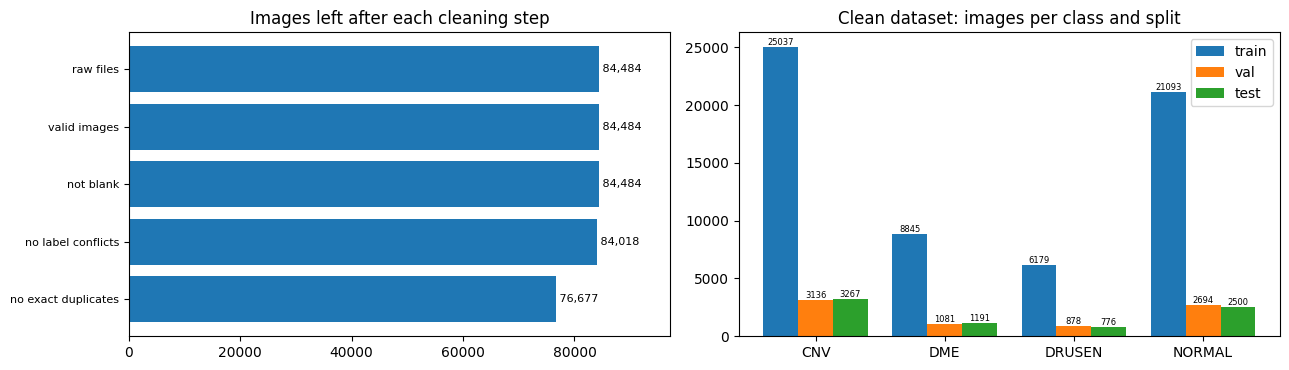

Patients and groups per split:
  train 61,154 images | 3,714 patients | 3,714 groups
  val    7,789 images |   502 patients |   502 groups
  test   7,734 images |   440 patients |   440 groups


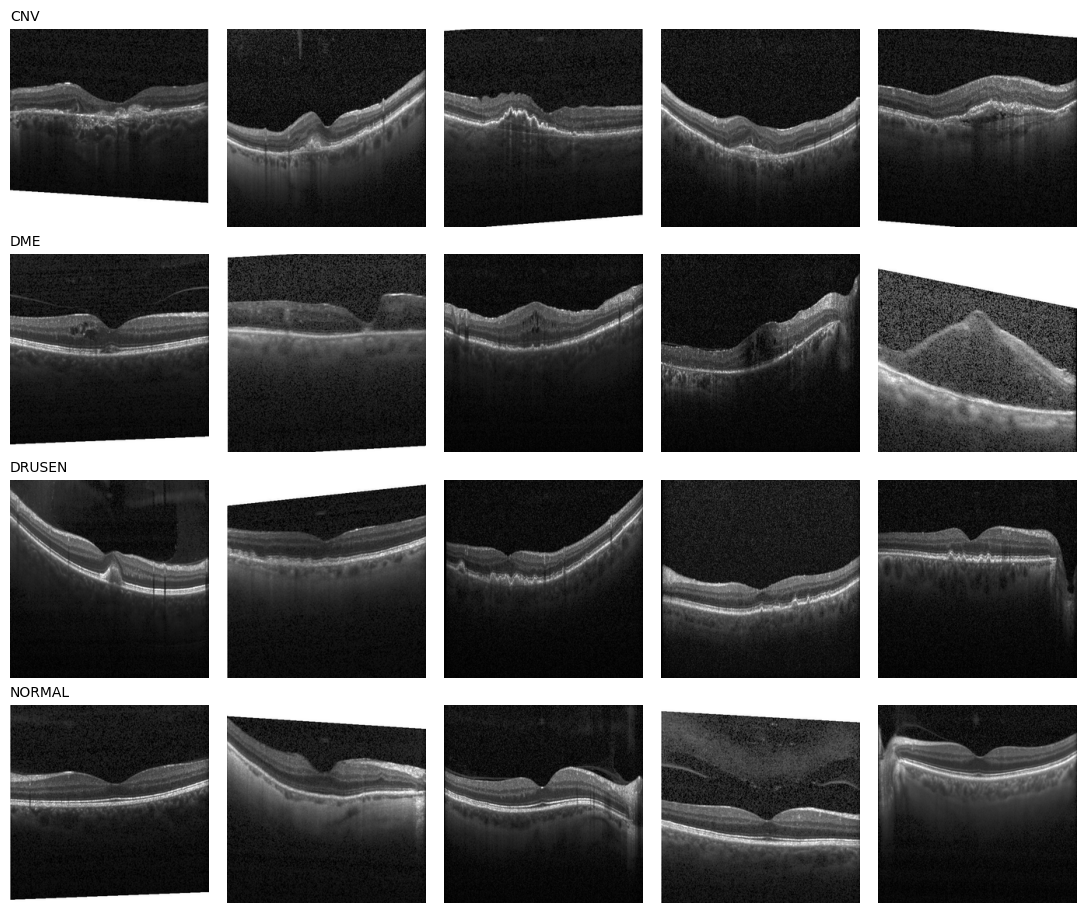


Train pixel mean 0.1930, std 0.2219 (0-1 scale)  |  class weights: CNV 0.61, DME 1.73, DRUSEN 2.47, NORMAL 0.72
Original image width alone predicts the clean test class with 41.3% accuracy (chance 25%).
If that is far above chance, try RESIZE_MODE = 'center_crop' or 'pad' and re-run with FORCE = True.

Saved stats.json and README.md in C:\Users\User\Desktop\retinaldataset\OCT_clean


In [9]:
# funnel and class balance
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
labels = [l for l, _ in FUNNEL]
vals = [n for _, n in FUNNEL]
axs[0].barh(range(len(vals)), vals, color="tab:blue")
axs[0].set_yticks(range(len(vals))); axs[0].set_yticklabels(labels, fontsize=8); axs[0].invert_yaxis()
for y, v in enumerate(vals):
    axs[0].text(v, y, f" {v:,}", va="center", fontsize=8)
axs[0].set_title("Images left after each cleaning step"); axs[0].set_xlim(0, max(vals) * 1.15)

x = np.arange(len(CLASSES)); wd = 0.27
for k, s in enumerate(("train", "val", "test")):
    cnt = [sum(1 for r in M if r["split"] == s and r["cls"] == c) for c in CLASSES]
    b = axs[1].bar(x + (k - 1) * wd, cnt, wd, label=s)
    axs[1].bar_label(b, fontsize=6)
axs[1].set_xticks(x); axs[1].set_xticklabels(CLASSES); axs[1].set_title("Clean dataset: images per class and split"); axs[1].legend()
plt.tight_layout(); plt.show()

print("Patients and groups per split:")
for s in ("train", "val", "test"):
    rows = [r for r in M if r["split"] == s]
    print(f"  {s:5s} {len(rows):6,d} images | {len({r['patient'] for r in rows}):5,d} patients | {len({r['group'] for r in rows}):5,d} groups")

# sample grid from the clean dataset
rng = np.random.default_rng(0)
fig, axs = plt.subplots(K, 5, figsize=(11, 2.3 * K), squeeze=False)
for r_i, c in enumerate(CLASSES):
    pool = [r for r in M if r["cls"] == c and r["split"] == "train"]
    for c_i, row in enumerate(rng.choice(len(pool), size=5, replace=False)):
        axs[r_i, c_i].imshow(Image.open(OUT_ROOT / pool[row]["path"]), cmap="gray"); axs[r_i, c_i].axis("off")
        if c_i == 0:
            axs[r_i, c_i].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

# dataset statistics for normalisation (train split only)
tr_rows = [r for r in M if r["split"] == "train"]
pick = rng.choice(len(tr_rows), size=min(4000, len(tr_rows)), replace=False)
acc, acc2, n_px = 0.0, 0.0, 0
for k in pick:
    a = np.asarray(Image.open(OUT_ROOT / tr_rows[k]["path"]), dtype=np.float64) / 255.0
    acc += a.sum(); acc2 += (a ** 2).sum(); n_px += a.size
mean = acc / n_px
std = math.sqrt(max(acc2 / n_px - mean ** 2, 0.0))
counts = {c: sum(1 for r in tr_rows if r["cls"] == c) for c in CLASSES}
stats = {"mean": mean, "std": std, "classes": CLASSES, "train_class_counts": counts,
         "class_weights": {c: len(tr_rows) / (K * n) for c, n in counts.items()},
         "image_size": OUT_SIZE, "split_mode": SPLIT_MODE, "resize_mode": RESIZE_MODE, "format": EXT,
         "n_images": len(M), "n_train": len(tr_rows)}
json.dump(stats, open(OUT_ROOT / "stats.json", "w"), indent=2)
print(f"\nTrain pixel mean {mean:.4f}, std {std:.4f} (0-1 scale)  |  class weights: " +
      ", ".join(f"{c} {w:.2f}" for c, w in stats["class_weights"].items()))

# does the original image width still give the class away?
by_w = collections.defaultdict(collections.Counter)
for r in tr_rows:
    by_w[r["orig_w"]][r["cls"]] += 1
maj = {w: c.most_common(1)[0][0] for w, c in by_w.items()}
te_rows = [r for r in M if r["split"] == "test"]
hit = sum(maj.get(r["orig_w"]) == r["cls"] for r in te_rows)
print(f"Original image width alone predicts the clean test class with {hit / len(te_rows) * 100:.1f}% accuracy (chance {100 / K:.0f}%).")
print("If that is far above chance, try RESIZE_MODE = 'center_crop' or 'pad' and re-run with FORCE = True.")

# dataset card
card = f'''# OCT clean dataset
Built from: {RAW_ROOT}
Split mode: {SPLIT_MODE} | seed {SEED} | fractions {SPLIT_FRACS}
Images: {len(M):,} ({OUT_SIZE}x{OUT_SIZE}, grayscale, {EXT}, resize mode {RESIZE_MODE})
Classes: {", ".join(CLASSES)}

## Cleaning funnel
''' + "\n".join(f"- {l}: {n:,}" for l, n in FUNNEL) + '''

## Guarantees (verified on the written files)
''' + "\n".join(f"- {'PASS' if ok else 'FAIL'}: {name}" for name, ok, _ in CHECKS) + f'''

## Files
- train/ val/ test/ : images in class folders (torchvision ImageFolder compatible)
- manifest.csv : every image with its source file, patient, group, original size and hashes
- dropped.csv : every removed file and why
- stats.json : pixel mean/std and class weights of the train split

## Use
    from torchvision import datasets
    train = datasets.ImageFolder("{OUT_ROOT.as_posix()}/train", transform=...)
    # normalise with mean={mean:.4f}, std={std:.4f} (single channel)
'''
(OUT_ROOT / "README.md").write_text(card, encoding="utf-8")
print("\nSaved stats.json and README.md in", OUT_ROOT)

## What to do next
- Training notebooks read `OUT_ROOT/train`, `val`, `test` with `ImageFolder`. Because patients and duplicates cannot cross splits, **val and test scores can be trusted**.
- Check the two "image width alone predicts the class" lines above. If they are far above chance, rebuild with `RESIZE_MODE = "center_crop"` (or `"pad"`) and `FORCE = True`.
- `dropped.csv` lists every removed file with its reason, handy for the methods section of a paper.
- Keep the printed funnel (raw files -> clean dataset) for the paper: it documents the data quality of the public benchmark.